# 19 — Tangga Waktu Informasi: Mengapa Informasi Pasar Hari-t Menolong Hanya pada h = 1

**Latar belakang.** Notebook 03 menunjukkan struktur lead–lag: penutupan pasar **hari t** berkorelasi cukup kuat dengan return Antam **t+1** (DXY dan US10Y, negatif), sedangkan versi **lag-1** yang dipakai protokol utama hampir tidak berkorelasi. Notebook 15 (skenario B) menunjukkan akibatnya pada model: MSE return turun pada h = 1 tetapi tidak pada h ≥ 5. Notebook ini menyusunnya menjadi satu **tangga waktu informasi** dengan kontrol plasebo, ditambah dekomposisi per indikator (SHAP).

**Tiga anak tangga** (fitur Antam sama; yang berbeda hanya *kapan* penutupan lima indikator pasar diambil; FFR dan BI-Rate selalu lag-1):

| anak tangga | baris origin t memuat | layak saat meramal? |
|---|---|---|
| `lag1` | penutupan hari t−1 (protokol utama) | ya (konservatif) |
| `hari_t` | penutupan hari t (skenario B, notebook 15) | ya, bila harga Antam hari t+1 diumumkan setelah penutupan pasar AS |
| `plasebo_t1` | penutupan hari t+1 | **tidak**: informasi dari sesudah harga Antam t+1 diumumkan |

**Logika plasebo.** Harga Antam diumumkan setiap hari pukul 08.30 WIB (halaman resmi Logam Mulia; kutip tanggal akses di naskah), sedangkan penutupan pasar AS jatuh sekitar 03.00–06.00 WIB (bergantung indikator dan musim) pada pagi berikutnya, sebelum pengumuman itu. Maka untuk h = 1 (target = return Antam t → t+1), penutupan hari t **ada sebelum** harga t+1, sedangkan penutupan hari t+1 **terjadi sesudahnya**. Bila cerita "harga Antam menyerap informasi pasar global dalam sehari" benar, anak tangga `plasebo_t1` **tidak** boleh menolong pada h = 1. Bila plasebo menolong sebesar skenario B, ada yang salah dengan penyelarasan waktu data, dan klaim skenario B tidak boleh dipakai. (Pada h ≥ 2 plasebo memuat informasi di dalam jendela target, jadi hasilnya di sana bukan ujian kegagalan.)

**Harapan yang ditetapkan sebelum dijalankan.**

- **E1.** Pada h = 1, `hari_t` lebih baik dari `lag1`: median rasio < 1 dan ≥ 1 model lolos BH. *(Sudah terlihat di notebook 15; ini replikasi, bukan temuan baru.)*
- **E2.** Pada h = 1, `plasebo_t1` **tidak** lebih baik dari `lag1`: tidak ada model yang lolos BH dan perbaikan median plasebo kurang dari sepertiga perbaikan median `hari_t`. *(Satu-satunya uji yang belum pernah dilihat sebelumnya.)*
- **E3.** Pada h ≥ 5, `hari_t` tidak memberi perbaikan konsisten: tidak ada uji yang lolos BH. *(Sudah terlihat di notebook 15.)*

**Cakupan.** 10 model ML × 5 horizon. Run baru hanya untuk anak tangga `plasebo_t1` (50 run ML; ± 3 menit di lingkungan uji dengan 2 thread CPU); `lag1` dan `hari_t` dibaca dari hasil notebook 05–07 dan 15. SHAP memakan ± 9 menit di lingkungan yang sama (Random Forest dan ExtraTrees paling lama, ± 30–70 detik per model); total notebook ± 15–25 menit, bergantung mesin. DL tidak diikutkan pada plasebo (biaya besar, tidak mengubah pertanyaan). SHAP: tiga model pohon deterministik (LightGBM, Random Forest, ExtraTrees; XGBoost dikeluarkan karena `n_jobs=-1` tidak reprodusibel), h ∈ {1, 20}, 100 origin uji yang sama untuk semua anak tangga, latar belakang 50 baris train. Importance berbasis impurity dari berkas yang sudah ada ditampilkan sebagai pembanding indikatif untuk semua model ML.

**Status analisis: sekunder/eksploratif** (kecuali E2, yang diuji sekali dengan kriteria di atas). Tidak ada pemilihan model atau hiperparameter baru.

**Peringatan.** (i) Waktu penutupan per indikator **diasumsikan** (dataset tidak mencatat jam); korelasi lead–lag dan plasebo adalah pemeriksaan tidak langsung, bukan bukti jam publikasi. (ii) XGBoost tidak reprodusibel antar-run (± 1–2% MAE), jadi perbandingan lintas anak tangga untuk XGBoost mengandung derau sebesar itu. (iii) SHAP menjelaskan *perilaku model*, bukan sebab-akibat pasar. (iv) 10 model ML bukan 10 percobaan independen: kesalahan mereka berkorelasi.

In [1]:
import sys, os, json, time, warnings

# Batasi thread CPU supaya laptop tetap responsif. Default 2 thread; ubah lewat env TA_THREADS.
# Harus di kernel BARU (sebelum numpy aktif).
N_THREADS = int(os.environ.get('TA_THREADS', '2'))
for _v in ('OMP_NUM_THREADS', 'MKL_NUM_THREADS', 'OPENBLAS_NUM_THREADS'):
    os.environ.setdefault(_v, str(N_THREADS))

sys.path.insert(0, os.path.join('..'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import OUT, HORIZONS, SETUPS, ML_MODELS, DL_MODELS, ALL_MODELS, LANG, PROTOCOL, ML_REV, QUICK
from src import analysis as A, plots as P, stats as S, ekstra as X
from src.runners import load_data, data_fingerprint

P.set_lang(LANG)
RES = os.path.join(OUT, 'results')
FIGS = os.path.join(OUT, 'figures')
for _d in (RES, FIGS):
    os.makedirs(_d, exist_ok=True)

df, p, exo = load_data('..')
DATA_HASH = data_fingerprint(df)
print(f'Data: {len(p)} hari kerja, {p.index[0].date()} s.d. {p.index[-1].date()} | sidik jari {DATA_HASH}'
      + (' | MODE QUICK (hasil hanya uji kelancaran)' if QUICK else ''))
if not os.path.isdir(os.path.join(RES, 'runs')):
    raise FileNotFoundError('results/runs/ belum ada: jalankan notebook 05-07 (atau salin hasil referensi) terlebih dahulu.')


def simpan(fig, nama):
    P.save_fig(fig, nama, FIGS)
    plt.show()
    plt.close(fig)

from src import runners as R, explain as E
from src.pipeline import EXO_B_SAMEDAY, make_exo_scenario_b

SB_RUNS = os.path.join(RES, 'skenario_b', 'runs')
if not os.path.isdir(SB_RUNS) or not any(f.endswith('_pred.csv') for f in os.listdir(SB_RUNS)):
    raise FileNotFoundError('results/skenario_b/runs/ belum ada: jalankan notebook 15 terlebih dahulu.')

Data: 4325 hari kerja, 2010-01-05 s.d. 2026-08-03 | sidik jari 7aea8db80d44


## 1. Membangun anak tangga dan pagar kebocoran

`make_exo_lead(exo, 1)` harus **identik** dengan `make_exo_scenario_b` (pagar otomatis). `make_exo_lead(exo, 2)` menggeser lima kolom pasar satu hari lagi: baris t memuat penutupan hari t+1. Dua baris terakhir menjadi NaN dan gugur dari fitur, sehingga plasebo h = 1 kehilangan satu baris uji terakhir; semua perbandingan memakai **irisan baris uji yang sama**.

In [2]:
exo_t = X.make_exo_lead(exo, 1)
exo_p = X.make_exo_lead(exo, 2)
pd.testing.assert_frame_equal(exo_t, make_exo_scenario_b(exo))          # lead=1 identik skenario B
cols5 = EXO_B_SAMEDAY
assert np.allclose(exo_t[cols5].iloc[:-1].values, exo[cols5].iloc[1:].values)    # baris t = penutupan hari t
assert np.allclose(exo_p[cols5].iloc[:-2].values, exo[cols5].iloc[2:].values)    # baris t = penutupan hari t+1
assert exo_p[cols5].iloc[-2:].isna().all().all()
for c in exo.columns:                                                    # kolom lain tidak berubah
    if c not in cols5:
        assert exo_p[c].equals(exo[c]) and exo_t[c].equals(exo[c])
print('[OK] anak tangga dibangun dengan benar. Kolom yang digeser:', cols5, '| tetap lag-1:', [c for c in exo.columns if c not in cols5])

[OK] anak tangga dibangun dengan benar. Kolom yang digeser: ['dxy_ret', 'sp500_ret', 'usd_idr_ret', 'ihsg_ret', 'us10yr_diff'] | tetap lag-1: ['ffr_diff', 'bi_rate_diff']


## 2. Bukti korelasi dari notebook 03 (tanpa model)

Korelasi return Antam dengan indikator pada tiga posisi waktu yang sama dengan tiga anak tangga. Bila ceritanya benar, hanya `hari_t` yang berkorelasi kuat (DXY dan US10Y), sedangkan `lag1` dan `plasebo_t1` mendekati nol.

In [3]:
ll_path = os.path.join(RES, 'leadlag_waktu_informasi.csv')
if os.path.exists(ll_path):
    ll = pd.read_csv(ll_path, index_col=[0, 1])
    blok = ll.iloc[0:3].copy()          # korelasi return Antam hari t' dengan X(t'-2), X(t'-1), X(t')
    assert all(i[0] == 'korelasi_dengan_return_t' for i in blok.index), 'format berkas lead-lag berubah'
    blok.index = ['lag1 (dipakai protokol utama)', 'hari_t (skenario B)', 'plasebo_t1 (hari t+1)']
    blok.index.name = 'anak tangga'
    blok.to_csv(os.path.join(RES, 'tangga_waktu_korelasi.csv'))
    display(blok.round(3))
else:
    print('leadlag_waktu_informasi.csv belum ada (dibuat notebook 03); tabel korelasi dilewati.')

,dxy_ret,sp500_ret,usd_idr_ret,ihsg_ret,us10yr_diff,ffr_diff,bi_rate_diff
anak tangga,,,,,,,
lag1 (dipakai protokol utama),0.094,-0.074,0.032,-0.084,-0.022,-0.037,-0.049
hari_t (skenario B),-0.288,0.021,0.118,-0.033,-0.233,0.021,-0.012
plasebo_t1 (hari t+1),-0.062,-0.009,-0.050,0.035,-0.017,0.016,-0.005


## 3. Run baru: hanya anak tangga `plasebo_t1` (10 ML × horizon)

Konfigurasi model identik dengan run utama (`R.run_ml`, `ML_REV`, sidik jari data). Hasil tersimpan di `results/tangga_waktu/runs/` dan dilewati bila sudah ada (aman dijalankan ulang).

In [4]:
PL_RUNS = os.path.join(RES, X.PLACEBO_DIR, 'runs')


def run_pl(lb, m, h):
    return R.run_ml(p, exo_p, lb, m, h, rev=ML_REV, data_hash=DATA_HASH)


cnt = R.run_grid([(X.PLACEBO_LABEL, m, h) for m in ML_MODELS for h in HORIZONS], run_pl, PL_RUNS, rev=ML_REV, data_hash=DATA_HASH)
assert cnt['gagal'] == 0, cnt['daftar_gagal']

RUN  plasebo_t1/lightgbm/h1 ... Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[21]	valid_0's rmse: 0.00653636
OK MAE=13,327 (3.3s)
RUN  plasebo_t1/lightgbm/h5 ... Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[53]	valid_0's rmse: 0.012793
OK MAE=30,062 (0.3s)
RUN  plasebo_t1/lightgbm/h10 ... Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[90]	valid_0's rmse: 0.0184053
OK MAE=42,161 (0.4s)
RUN  plasebo_t1/lightgbm/h20 ... Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[5]	valid_0's rmse: 0.0245465
OK MAE=62,639 (0.2s)
RUN  plasebo_t1/lightgbm/h30 ... Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[24]	valid_0's rmse: 0.0281072
OK MAE=82,881 (0.3s)
RUN  plasebo_t1/xgboost/h1 ... OK MAE=13,281 (6.8s)
RUN  plasebo_t1/xgboost/h5 ... OK MAE=29,939 (

## 4. Tangga: setiap anak tangga vs Drift, Drift bergulir, dan lag-1

`rel` = rasio MSE-return (< 1 = lebih baik). Semua uji DM–HLN satu-sisi pada baris uji yang sama; `q_*` = BH atas semua model × horizon per anak tangga. Garis hitam tebal pada figur = median 10 model.

n_model  median_rasio_vs_drift  \
horizon anak_tangga                                   
1       lag1              10                  1.006   
        hari_t            10                  0.936   
        plasebo_t1        10                  1.016   
5       lag1              10                  0.996   
        hari_t            10                  0.996   
        plasebo_t1        10                  0.998   
10      lag1              10                  0.983   
        hari_t            10                  0.987   
        plasebo_t1        10                  0.989   
20      lag1              10                  0.977   
        hari_t            10                  0.987   
        plasebo_t1        10                  0.985   
30      lag1              10                  0.999   
        hari_t            10                  0.999   
        plasebo_t1        10                  1.000   

                     median_rasio_vs_drift_bergulir  n_lolos_BH_vs_drift  \
horizon anak_tangga                                                        
1       lag1                                  1.010                    0   
        hari_t                                0.939                    6   
        plasebo_t1                            1.020                    0   
5       lag1                                  1.020                    0   
        hari_t                                1.020                    0   
        plasebo_t1                            1.023                    0   
10      lag1                                  1.028                    0   
        hari_t                                1.031                    0   
        plasebo_t1                            1.033                    0   
20      lag1                                  1.066                    0   
        hari_t                                1.076                    0   
        plasebo_t1                            1.075                    0   
30      lag1                                  1.115                    0   
        hari_t                                1.115                    0   
        plasebo_t1                            1.117                    0   

                     n_lolos_BH_vs_bergulir  median_rasio_vs_lag1  \
horizon anak_tangga                                                 
1       lag1                              0                   NaN   
        hari_t                            5                 0.927   
        plasebo_t1                        0                 1.009   
5       lag1                              0                   NaN   
        hari_t                            0                 1.000   
        plasebo_t1                        0                 0.997   
10      lag1                              0                   NaN   
        hari_t                            0                 1.000   
        plasebo_t1                        0                 0.999   
20      lag1                              0                   NaN   
        hari_t                            0                 1.004   
        plasebo_t1                        0                 1.003   
30      lag1                              0                   NaN   
        hari_t                            0                 1.000   
        plasebo_t1                        0                 1.000   

                     n_lebih_baik_vs_lag1  n_lolos_BH_vs_lag1  
horizon anak_tangga                                            
1       lag1                          NaN                 NaN  
        hari_t                       10.0                 9.0  
        plasebo_t1                    2.0                 0.0  
5       lag1                          NaN                 NaN  
        hari_t                        5.0                 0.0  
        plasebo_t1                    7.0                 0.0  
10      lag1                          NaN                 NaN  
        hari_t                        5.0 

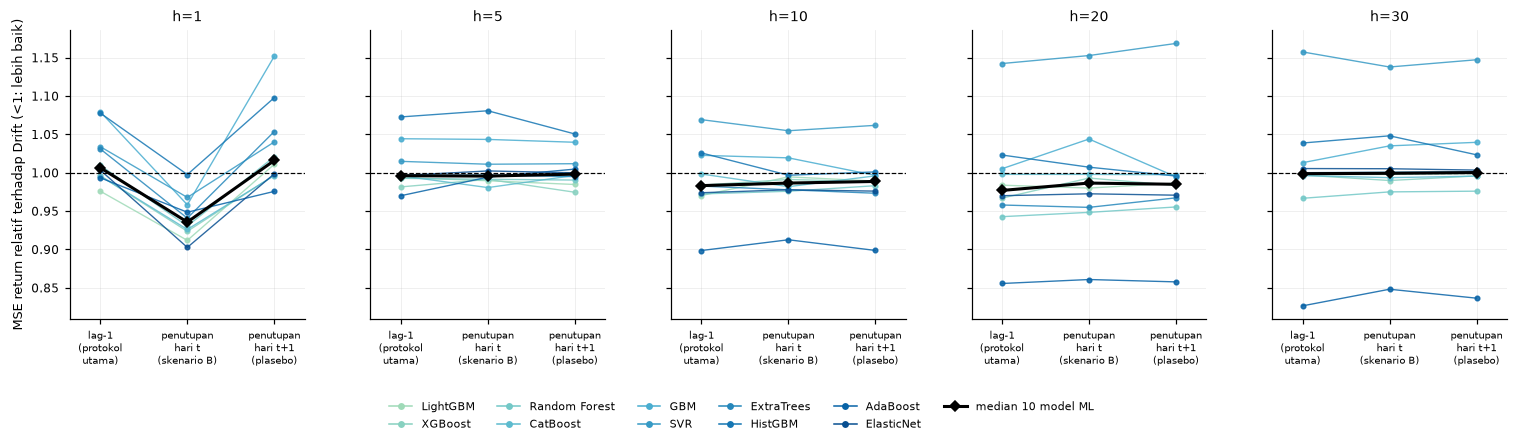

In [5]:
L = X.ladder_table(RES, p, ML_MODELS, HORIZONS)
assert len(L) == len(X.RUNG_ORDER) * len(ML_MODELS) * len(HORIZONS), 'ada run yang belum lengkap (jalankan notebook 07 dan 15, lalu sel run di atas)'
L.to_csv(os.path.join(RES, 'tangga_waktu_dm.csv'), index=False)

rows = []
for (h, r), g in L.groupby(['horizon', 'rung']):
    rows.append({'horizon': h, 'anak_tangga': r, 'n_model': len(g),
                 'median_rasio_vs_drift': g.rel_drift.median(), 'median_rasio_vs_drift_bergulir': g.rel_roll.median(),
                 'n_lolos_BH_vs_drift': int((g.q_drift < 0.05).sum()), 'n_lolos_BH_vs_bergulir': int((g.q_roll < 0.05).sum()),
                 'median_rasio_vs_lag1': g.rel_lag1.median() if r != 'lag1' else np.nan,
                 'n_lebih_baik_vs_lag1': int((g.rel_lag1 < 1).sum()) if r != 'lag1' else np.nan,
                 'n_lolos_BH_vs_lag1': int((g.q_lag1 < 0.05).sum()) if r != 'lag1' else np.nan})
RING = pd.DataFrame(rows)
order_r = {r: i for i, r in enumerate(X.RUNG_ORDER)}
RING = RING.sort_values(['horizon', 'anak_tangga'], key=lambda s: s.map(order_r) if s.name == 'anak_tangga' else s).reset_index(drop=True)
RING.to_csv(os.path.join(RES, 'tangga_waktu_ringkasan.csv'), index=False)
display(RING.round(3).set_index(['horizon', 'anak_tangga']))

fig = X.fig_timing_ladder(L, ML_MODELS, HORIZONS)
simpan(fig, 'fig_tangga_waktu')

### Pemeriksaan harapan E1–E3 (kriteria di sel pertama)

In [6]:
def _sel(h, r):
    return L[(L.horizon == h) & (L.rung == r)]


chk = []
if 1 in HORIZONS:
    gb, gp = _sel(1, 'hari_t'), _sel(1, 'plasebo_t1')
    chk.append({'harapan': 'E1  hari_t lebih baik dari lag1 pada h=1',
                'ukuran': f'median rasio {gb.rel_lag1.median():.3f}; {int((gb.rel_lag1 < 1).sum())}/{len(gb)} model < 1; {int((gb.q_lag1 < 0.05).sum())} lolos BH',
                'terpenuhi': bool(gb.rel_lag1.median() < 1 and (gb.q_lag1 < 0.05).sum() >= 1)})
    gain_b, gain_p = 1 - gb.rel_lag1.median(), 1 - gp.rel_lag1.median()
    chk.append({'harapan': 'E2  plasebo TIDAK lebih baik dari lag1 pada h=1',
                'ukuran': (f'median rasio {gp.rel_lag1.median():.3f}; {int((gp.rel_lag1 < 1).sum())}/{len(gp)} model < 1; '
                           f'{int((gp.q_lag1 < 0.05).sum())} lolos BH; perbaikan median {100 * gain_p:.1f}% vs {100 * gain_b:.1f}% (hari_t)'),
                'terpenuhi': bool((gp.q_lag1 < 0.05).sum() == 0 and gain_p < gain_b / 3)})
gh = L[(L.rung == 'hari_t') & (L.horizon >= 5)]
if len(gh):
    chk.append({'harapan': 'E3  hari_t tidak memberi perbaikan konsisten pada h>=5',
                'ukuran': f'{int((gh.q_lag1 < 0.05).sum())}/{len(gh)} uji lolos BH; median rasio {gh.rel_lag1.median():.3f}',
                'terpenuhi': bool((gh.q_lag1 < 0.05).sum() == 0)})
CHK = pd.DataFrame(chk)
CHK.to_csv(os.path.join(RES, 'tangga_waktu_harapan.csv'), index=False)
pd.set_option('display.max_colwidth', 200)
display(CHK.set_index('harapan'))
if not CHK.terpenuhi.all():
    print('[PERHATIAN] ada harapan yang tidak terpenuhi: laporkan apa adanya dan jangan memakai klaim terkait (lihat "Cara membaca").')

,ukuran,terpenuhi
harapan,,
E1 hari_t lebih baik dari lag1 pada h=1,median rasio 0.927; 10/10 model < 1; 9 lolos BH,True
E2 plasebo TIDAK lebih baik dari lag1 pada h=1,median rasio 1.009; 2/10 model < 1; 0 lolos BH; perbaikan median -0.9% vs 7.3% (hari_t),True
E3 hari_t tidak memberi perbaikan konsisten pada h>=5,0/40 uji lolos BH; median rasio 1.001,True


## 5. Dekomposisi per indikator: SHAP (model pohon) dan importance impurity

Model dilatih ulang secara deterministik (konfigurasi identik dengan run utama) dan prediksinya **dicocokkan** dengan prediksi tersimpan (`repro_maxrel_diff`); latar belakang = baris train, sampel yang dijelaskan = 100 origin uji yang tersebar merata dan sama untuk semua anak tangga. Porsi = rata-rata |SHAP| per variabel (fitur turunan dijumlahkan per variabel), dirata-rata atas tiga model.

In [7]:
shap_h = [h for h in X.SHAP_H if h in HORIZONS]
rung_exo = {'lag1': exo, 'hari_t': exo_t, 'plasebo_t1': exo_p}
SH_ROWS, SH_INFO = [], []
for h in shap_h:
    for rung in X.RUNG_ORDER:
        lb, sub = X.RUNG_SPEC[rung]
        for m in X.SHAP_MODELS:
            t0 = time.time()
            tab, info = X.shap_rung(p, rung_exo[rung], m, h, stored_pred=A.read_pred(RES, lb, m, h, sub))
            tab['rung'] = rung
            SH_ROWS.append(tab)
            SH_INFO.append({'rung': rung, 'horizon': h, 'model': m, **info, 'detik': round(time.time() - t0, 1)})
            rd = info['repro_maxrel_diff']
            print(f"SHAP {rung:<11} h={h:<2} {m:<12} {info['method']:<18} selisih prediksi vs tersimpan (maks relatif)="
                  f"{'n/a' if rd is None else format(rd, '.1e')}  {SH_INFO[-1]['detik']}s")
SH = pd.concat(SH_ROWS, ignore_index=True)
INFO = pd.DataFrame(SH_INFO)
SH.to_csv(os.path.join(RES, 'tangga_waktu_shap_porsi.csv'), index=False)
INFO.to_csv(os.path.join(RES, 'tangga_waktu_shap_info.csv'), index=False)
bad = INFO[INFO.repro_maxrel_diff.fillna(0) > 0.01]
if len(bad):
    print('[PERHATIAN] model yang dilatih ulang berbeda > 1% dari run tersimpan; laporkan:')
    display(bad)

Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[33]	valid_0's rmse: 0.00653903
SHAP lag1        h=1  lightgbm     TreeExplainer      selisih prediksi vs tersimpan (maks relatif)=1.5e-16  3.4s
SHAP lag1        h=1  rf           TreeExplainer      selisih prediksi vs tersimpan (maks relatif)=1.5e-16  67.3s
SHAP lag1        h=1  extra_trees  TreeExplainer      selisih prediksi vs tersimpan (maks relatif)=1.5e-16  111.1s
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[156]	valid_0's rmse: 0.00563125
SHAP hari_t      h=1  lightgbm     TreeExplainer      selisih prediksi vs tersimpan (maks relatif)=1.5e-16  0.9s
SHAP hari_t      h=1  rf           TreeExplainer      selisih prediksi vs tersimpan (maks relatif)=1.5e-16  54.2s
SHAP hari_t      h=1  extra_trees  TreeExplainer      selisih prediksi vs tersimpan (maks relatif)=1.5e-16  72.4s
Training until validation scores don't improve for 50 rounds

Porsi |SHAP| (%) per variabel, rata-rata LightGBM / Random Forest / ExtraTrees:


variabel            emas   dxy  sp500  usd_idr  ihsg  us10yr  ffr  bi_rate  \
horizon rung                                                                 
1       lag1        45.3  20.8    9.2      2.2  11.4     5.6  1.5      4.0   
        hari_t      19.8  33.1    1.8     12.1   4.2    27.0  1.1      0.9   
        plasebo_t1  59.2  13.1    2.7      3.4   9.3     6.1  2.3      3.8   
20      lag1        75.0   4.7    7.4      3.5   4.0     4.4  0.6      0.4   
        hari_t      60.8   4.9   10.7      6.3   4.5    12.2  0.2      0.4   
        plasebo_t1  69.5   6.3    7.6      4.7   5.3     5.6  0.6      0.4   

variabel            pasar_hari_t_5_indikator  
horizon rung                                  
1       lag1                            49.3  
        hari_t                          78.3  
        plasebo_t1                      34.7  
20      lag1                            24.0  
        hari_t                          38.5  
        plasebo_t1                      29.5

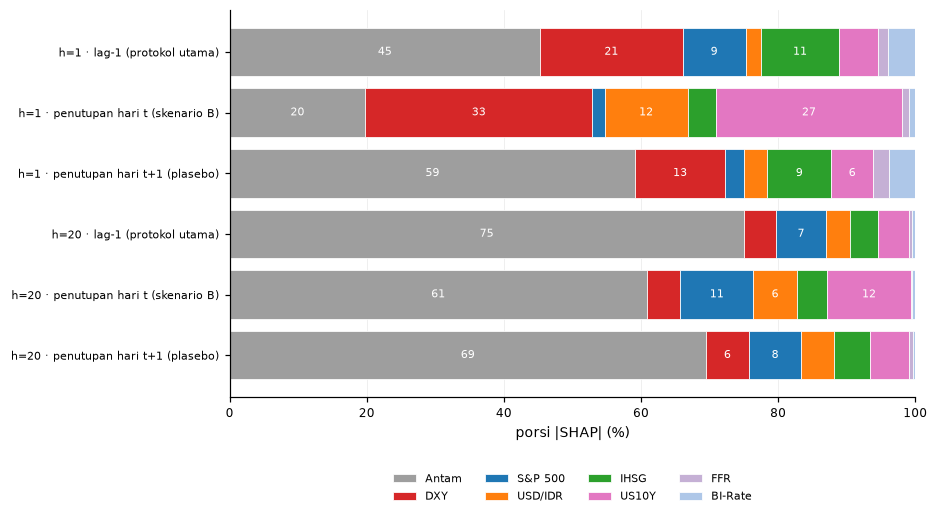


Pembanding indikatif: porsi importance impurity/gain (%), rata-rata model ML yang punya importance (bukan SHAP):


variabel            emas   dxy  sp500  usd_idr  ihsg  us10yr  ffr  bi_rate  \
horizon rung                                                                 
1       hari_t      50.1  15.7    4.1      7.9   4.0    15.5  1.1      1.7   
        lag1        64.4   6.9    8.5      2.7   7.7     4.9  1.4      3.5   
        plasebo_t1  66.2   5.6    3.9      3.2   5.8     8.8  2.0      4.5   
5       hari_t      61.6   7.7    4.9      8.2   8.2     8.3  1.1      0.1   
        lag1        66.6   9.4    7.5      4.2   6.9     3.5  1.4      0.5   
        plasebo_t1  61.1   7.3    5.8      6.7   8.1     9.2  1.6      0.2   
10      hari_t      60.4   4.5   12.2      6.7   8.2     6.4  0.4      1.2   
        lag1        59.1   6.0   17.5      3.2   8.5     3.1  0.6      2.0   
        plasebo_t1  57.9   5.3   14.5      5.7   7.6     7.1  0.7      1.3   
20      hari_t      61.1   5.9   14.6      5.6   3.7     7.7  0.5      0.9   
        lag1        63.7   3.1   20.5      4.3   4.6     2.5  0.3      1.0   
        plasebo_t1  58.9   5.1   18.9      6.2   4.3     5.8  0.2      0.7   
30      hari_t      72.4   2.8    9.5      5.1   3.5     5.5  0.5      0.7   
        lag1        76.7   2.3   10.5      3.3   2.8     3.0  0.5      0.8   
        plasebo_t1  71.9   3.1    9.8      4.7   3.3     6.1  0.2      0.9   

variabel            n_model  
horizon rung                 
1       hari_t            8  
        lag1              8  
        plasebo_t1        8  
5       hari_t            8  
        lag1              8  
        plasebo_t1        8  
10      hari_t            8  
        lag1              8  
        plasebo_t1        8  
20      hari_t            8  
        lag1              8  
        plasebo_t1        8  
30      hari_t            8  
        lag1              8  
        plasebo_t1        8

In [8]:
pv = SH.groupby(['horizon', 'rung', 'variabel']).porsi_pct.mean().unstack('variabel')
pv = pv.reindex(index=pd.MultiIndex.from_product([shap_h, X.RUNG_ORDER], names=['horizon', 'rung']))[E.GROUP_ORDER]
pv['pasar_hari_t_5_indikator'] = pv[['dxy', 'sp500', 'usd_idr', 'ihsg', 'us10yr']].sum(axis=1)
print('Porsi |SHAP| (%) per variabel, rata-rata LightGBM / Random Forest / ExtraTrees:')
display(pv.round(1))
fig = X.fig_timing_shap(SH, shap_h)
simpan(fig, 'fig_tangga_waktu_shap')

FI = X.fimp_share_table(RES, ML_MODELS, HORIZONS)
FI.to_csv(os.path.join(RES, 'tangga_waktu_impurity_porsi.csv'), index=False)
fi = FI.groupby(['horizon', 'rung', 'variabel']).porsi_pct.mean().unstack('variabel')[E.GROUP_ORDER]
fi['n_model'] = FI.groupby(['horizon', 'rung']).model.nunique()
print('\nPembanding indikatif: porsi importance impurity/gain (%), rata-rata model ML yang punya importance (bukan SHAP):')
display(fi.round(1))

**Cara membaca.**

- **Tangga.** Cerita yang konsisten dengan data bila E1–E3 terpenuhi: informasi pasar hari t menurunkan MSE hanya pada h = 1, plasebo tidak menolong di sana, dan tidak ada perbaikan konsisten pada h ≥ 5. Ini mendukung tafsiran **"harga Antam menyerap informasi pasar global dalam sehari"**, dan menjelaskan mengapa protokol utama (lag-1) hampir tidak menemukan apa pun: informasi yang berguna sudah terserap sebelum horizon yang lebih panjang. Itu **tafsiran yang konsisten dengan data**, bukan bukti sebab-akibat.
- **Bila E2 tidak terpenuhi** (plasebo menolong pada h = 1), jangan pakai klaim skenario B: periksa penyelarasan tanggal data (notebook 01–02) dan waktu publikasi harga sebelum menulis apa pun.
- **SHAP.** Bandingkan porsi DXY dan US10Y pada `lag1` vs `hari_t` di h = 1: bila naik jauh, model *memakai* informasi segar itu; pada `plasebo_t1` porsi itu tidak ikut naik (informasi yang belum ada tidak berhubungan dengan target). Pada h = 20 porsi indikator pasar total (`pasar_hari_t_5_indikator`) juga ikut naik di `hari_t` (run referensi: ± 24% → ± 39%), **tetapi MSE tidak membaik** (tabel tangga): model memakai informasi itu tanpa keuntungan di luar sampel. Jadi porsi SHAP menunjukkan apa yang *dipakai* model, bukan apa yang *berguna*; ukuran kegunaan adalah tangga MSE di atas. Model ML bergantung kuat pada fitur Antam sendiri; jangan menafsirkan porsi kecil sebagai "indikator tidak penting" tanpa melihat apakah modelnya sendiri lebih baik dari Drift (notebook 10).
- **Selisih prediksi vs tersimpan** pada log SHAP harus ≈ 0 untuk LightGBM, Random Forest, dan ExtraTrees; bila > 1% sel akan memberi peringatan. Laporkan bila terjadi.
- **Kalimat yang aman untuk naskah:** "Pada h = 1, mengganti indikator pasar ber-lag-1 dengan penutupan hari t menurunkan MSE return median sebesar X% dan meningkatkan porsi atribusi DXY dan US10Y dari A% menjadi B%; kontrol plasebo (penutupan hari t+1) tidak memberi perbaikan, sedangkan pada h ≥ 5 tidak ada perbaikan yang lolos koreksi BH." Isi X, A, B dari tabel di atas. Cantumkan asumsi jam publikasi (08.30 WIB) dan sumbernya.
- **Yang tidak boleh ditulis:** "indikator makro menyebabkan pergerakan emas", atau menjadikan skenario B pengganti protokol utama. Skenario B adalah analisis sensitivitas waktu informasi.